In [1]:
%matplotlib inline

import os
from pathlib import Path

import numpy as np
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica Neue']

In [2]:
DATA_DIR = Path.cwd().parent / "data"
FIG_DIR = Path.cwd().parent / "figures"
MODELS = {
    "woodbury_full": "DFR-MB",
    "woodbury_td":   "DFR-TD",
    "sr_td":         "SR-TD",
    "sr_sf":         "SR-SF",
}
COLORS = {
    "woodbury_full": "black",
    "woodbury_td":   "cornflowerblue",
    "sr_td":         "lightsteelblue",
    "sr_sf":         "slategrey",
}

# Environment visualizations

In [245]:
plt.rcParams['axes.linewidth'] = 3.0

## Four-room

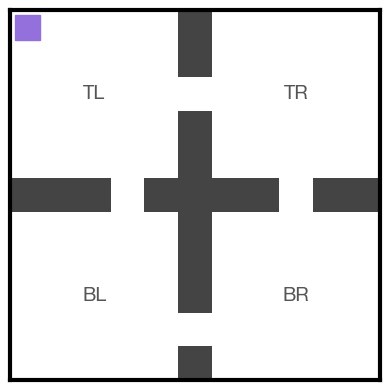

In [217]:
save_path = FIG_DIR / 'mazes/four-room.png'
# save_path = None

ROWS, COLS = 11, 11

# Compute wall and doorway states exactly as make_four_room does
h_wall = [5 * COLS + c for c in range(COLS) if c not in (3, 8)]
v_wall = [r * COLS + 5  for r in range(ROWS) if r not in (2, 5, 9)]
wall_set    = set(h_wall + v_wall)
doorway_set = {2*COLS+5, 5*COLS+3, 9*COLS+5, 5*COLS+8}  # 27, 58, 104, 63

START = 0   # state (0,0) — TL corner

# Build grid image: 0 = room, 1 = wall, 2 = doorway
grid = np.zeros((ROWS, COLS), dtype=float)
for s in wall_set:
    r, c = divmod(s, COLS)
    grid[r, c] = 1.0

fig, ax = plt.subplots(figsize=(4, 4))

cmap = ListedColormap(["white", "#444444", "#6abf69"])
ax.imshow(grid, cmap=cmap, vmin=0, vmax=2, origin='upper', interpolation='nearest')

# Grid lines
# for x in range(COLS + 1):
#     ax.axvline(x - 0.5, color='grey', lw=0.4)
# for y in range(ROWS + 1):
#     ax.axhline(y - 0.5, color='grey', lw=0.4)

# Mark START state
sr, sc = divmod(START, COLS)
ax.plot(sc, sr, 's', ms=18, color='mediumpurple', zorder=5)

# # Annotate doorways with state numbers
# for s in sorted(doorway_set):
#     r, c = divmod(s, COLS)
#     ax.text(c, r, str(s), ha='center', va='center',
#             fontsize=7, color='white', fontweight='bold')

# Room labels
for label, rr, rc in [("TL", 2, 2), ("TR", 2, 8), ("BL", 8, 2), ("BR", 8, 8)]:
    ax.text(rc, rr, label, ha='center', va='center',
            fontsize=14, color='#555555', fontweight='bold', alpha=1.0)

# ax.set_xticks(np.arange(COLS))
# ax.set_yticks(np.arange(ROWS))
# ax.set_title("Four-room environment", fontsize=14)
ax.tick_params(length=0)

plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\m'
/var/folders/sf/4_xlxj4j2r1_sx5v07843wbw0000gn/T/ipykernel_19534/1954853527.py:45: SyntaxWarning: invalid escape sequence '\m'
  ax.text(c, r, f'$\mathrm{{r}}_{label}$', ha='center', va='center',


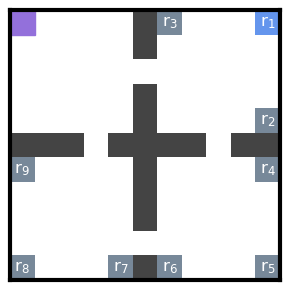

In [218]:
save_path = FIG_DIR / 'mazes/four-room-goals.png'
# save_path = None

ROWS, COLS = 11, 11

h_wall = [5 * COLS + c for c in range(COLS) if c not in (3, 8)]
v_wall = [r * COLS + 5  for r in range(ROWS) if r not in (2, 5, 9)]
wall_set = set(h_wall + v_wall)

grid = np.zeros((ROWS, COLS), dtype=float)
for s in wall_set:
    r, c = divmod(s, COLS)
    grid[r, c] = 1.0

fig, ax = plt.subplots(figsize=(3, 3))

cmap = ListedColormap(["white", "#444444"])
ax.imshow(grid, cmap=cmap, vmin=0, vmax=1, origin='upper', interpolation='nearest')

CORNER_BLUE = 'cornflowerblue'
CORNER_GRAY = 'lightslategray'

corner_cells = [
    # TR room
    (0, 10, 1),   # <- blue
    (4, 10, 2),
    (0,  6, 3),
    # BR room
    (6, 10, 4),
    (10,10, 5),
    (10, 6, 6),
    # BL room
    (10, 4, 7),
    (10, 0, 8),
    (6,  0, 9),
]

# Mark START state
sr, sc = divmod(START, COLS)
ax.plot(sc, sr, 's', ms=18, color='mediumpurple', zorder=1)

for r, c, label in corner_cells:
    color = CORNER_BLUE if label == 1 else CORNER_GRAY
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=color, zorder=2))
    ax.text(c, r, f'$\mathrm{{r}}_{label}$', ha='center', va='center',
            fontsize=12, color='white', fontweight='bold', zorder=3)

ax.tick_params(length=0)
plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

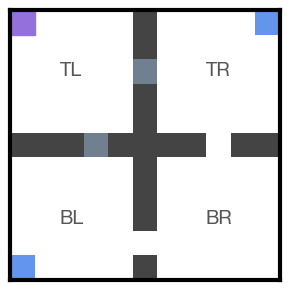

In [220]:
save_path = FIG_DIR / 'mazes/four-room-walls.png'
# save_path = None

ROWS, COLS = 11, 11

h_wall = [5 * COLS + c for c in range(COLS) if c not in (3, 8)]
v_wall = [r * COLS + 5  for r in range(ROWS) if r not in (2, 5, 9)]
wall_set    = set(h_wall + v_wall)
doorway_set = {2*COLS+5, 5*COLS+3, 9*COLS+5, 5*COLS+8}  # 27, 58, 104, 63

START = 0

grid = np.zeros((ROWS, COLS), dtype=float)
for s in wall_set:
    r, c = divmod(s, COLS)
    grid[r, c] = 1.0

fig, ax = plt.subplots(figsize=(3, 3))

cmap = ListedColormap(["white", "#444444"])
ax.imshow(grid, cmap=cmap, vmin=0, vmax=1, origin='upper', interpolation='nearest')

GOAL_COLOR = 'cornflowerblue'
for r, c in [(0, 10), (10, 0)]:
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=GOAL_COLOR, zorder=2))

DOOR_COLOR = 'Slategrey'
for s in [2*COLS+5, 5*COLS+3]:   # states 27, 58
    r, c = divmod(s, COLS)
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=DOOR_COLOR, zorder=2))

# START marker
sr, sc = divmod(START, COLS)
ax.plot(sc, sr, 's', ms=18, color='mediumpurple', zorder=1)

for label, rr, rc in [("TL", 2, 2), ("TR", 2, 8), ("BL", 8, 2), ("BR", 8, 8)]:
    ax.text(rc, rr, label, ha='center', va='center',
            fontsize=14, color='#555555', fontweight='bold', alpha=1.0)

ax.tick_params(length=0)
plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

## Open-field horizontal barrier

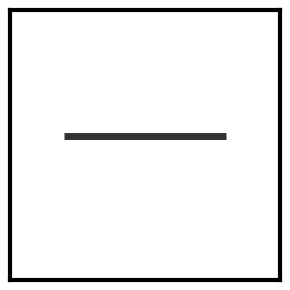

In [ ]:
save_path = FIG_DIR / 'mazes/open-field-H.png'

# Geometry matches plan_open_horizontal.py
ROWS_H, COLS_H  = 15, 15
BARRIER_ROW     = ROWS_H // 2        # 7  — wall sits between rows 6 and 7
COL_START       = 3
COL_END         = 12                 # wall covers cols 3..11

# Evaluation regions
START_ROW_MIN, START_ROW_MAX = 3, 5
START_COL_MIN, START_COL_MAX = 5, 9
GOAL_ROW_MIN,  GOAL_ROW_MAX  = 8, 10
GOAL_COL_MIN,  GOAL_COL_MAX  = 5, 9

fig, ax = plt.subplots(figsize=(4, 4))

# White grid
ax.imshow(np.zeros((ROWS_H, COLS_H)), cmap='Greys', vmin=0, vmax=1,
          origin='upper', interpolation='nearest', aspect='equal')

# Light cell grid
# for x in range(COLS_H + 1):
#     ax.axvline(x - 0.5, color='lightgrey', lw=0.5)
# for y in range(ROWS_H + 1):
#     ax.axhline(y - 0.5, color='lightgrey', lw=0.5)

# Shade start region (rows 3–5, cols 5–9)
ax.add_patch(Rectangle(
    (START_COL_MIN - 0.5, START_ROW_MIN - 0.5),
    START_COL_MAX - START_COL_MIN + 1,
    START_ROW_MAX - START_ROW_MIN + 1,
    facecolor='slategrey', alpha=0.2, zorder=0
))

# Shade goal region (rows 8–10, cols 5–9)
ax.add_patch(Rectangle(
    (GOAL_COL_MIN - 0.5, GOAL_ROW_MIN - 0.5),
    GOAL_COL_MAX - GOAL_COL_MIN + 1,
    GOAL_ROW_MAX - GOAL_ROW_MIN + 1,
    facecolor='royalblue', alpha=0.2, zorder=0
))

# Horizontal barrier: thick wall between rows 6 and 7, cols 3..11
ax.plot([COL_START - 0.5, COL_END - 0.5],
        [BARRIER_ROW - 0.5, BARRIER_ROW - 0.5],
        color='#333333', lw=5, solid_capstyle='butt', zorder=3)

ax.set_xticks(np.arange(COLS_H))
ax.set_yticks(np.arange(ROWS_H))
ax.set_xticklabels(np.arange(COLS_H), fontsize=6)
ax.set_yticklabels(np.arange(ROWS_H), fontsize=6)
# ax.set_title("Open-field: horizontal barrier", fontsize=14)
ax.tick_params(length=0)
ax.text((START_COL_MIN + START_COL_MAX) / 2, (START_ROW_MIN + START_ROW_MAX) / 2,
        "start region", ha='center', va='center', fontsize=14, color='black', fontweight='bold')
ax.text((GOAL_COL_MIN + GOAL_COL_MAX) / 2, (GOAL_ROW_MIN + GOAL_ROW_MAX) / 2,
        "goal region", ha='center', va='center', fontsize=14, color='black', fontweight='bold')

plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

## Open-field L barrier

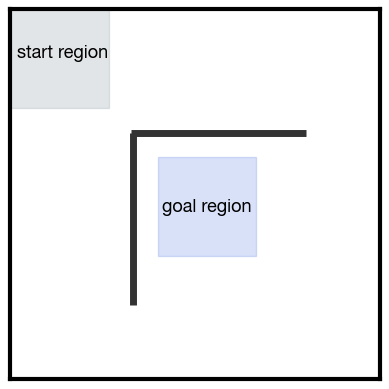

In [225]:
save_path = FIG_DIR / 'mazes/open-field-L.png'

# Geometry matches plan_open_angle.py
ROWS_L, COLS_L = 15, 15
CORNER_ROW = 5
CORNER_COL = 5
H_END_COL  = 12   # horizontal arm: cols [CORNER_COL, H_END_COL) = 5..11
V_END_ROW  = 12   # vertical arm:   rows [CORNER_ROW, V_END_ROW) = 5..11

fig, ax = plt.subplots(figsize=(4, 4))

# White grid
ax.imshow(np.zeros((ROWS_L, COLS_L)), cmap='Greys', vmin=0, vmax=1,
          origin='upper', interpolation='nearest', aspect='equal')

# Light cell grid lines
# for x in range(COLS_L + 1):
#     ax.axvline(x - 0.5, color='lightgrey', lw=0.5)
# for y in range(ROWS_L + 1):
#     ax.axhline(y - 0.5, color='lightgrey', lw=0.5)

# Shade start region (top-left: rows 0..CORNER_ROW-1, cols 0..CORNER_COL-1)
ax.fill_betweenx(
    [-0.5, CORNER_ROW-1 - 0.5],
    -0.5, CORNER_COL-1 - 0.5,
    color='slategrey', alpha=0.2
)

# Shade goal region (bottom-right: rows V_END_ROW..end, cols H_END_COL..end)
ax.fill_betweenx(
    [6 - 0.5, 10 - 0.5],
    6 - 0.5, 10 - 0.5,
    color='royalblue', alpha=0.2
)

# L-shaped barrier: horizontal arm + vertical arm (meet at corner)
wall_kw = dict(color='#333333', lw=5, solid_capstyle='butt', zorder=3)
ax.plot([CORNER_COL - 0.6, H_END_COL - 0.5],
        [CORNER_ROW - 0.5, CORNER_ROW - 0.5], **wall_kw)   # horizontal arm
ax.plot([CORNER_COL - 0.5, CORNER_COL - 0.5],
        [CORNER_ROW - 0.5, V_END_ROW - 0.5],  **wall_kw)   # vertical arm

ax.set_xticks(np.arange(COLS_L))
ax.set_yticks(np.arange(ROWS_L))
ax.set_xticklabels(np.arange(COLS_L), fontsize=6)
ax.set_yticklabels(np.arange(ROWS_L), fontsize=6)
# ax.set_title("Open-field: L-shaped barrier", fontsize=14)
ax.tick_params(length=0)

ax.text(1.65, 1.25, "start region",
        ha='center', va='center', fontsize=13, color='black', alpha=1.0)
ax.text(7.5,7.5, "goal region",
        ha='center', va='center', fontsize=13, color='black', alpha=1.0)

plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# Reconstruction loss

In [248]:
plt.rcParams['axes.linewidth'] = 1.5

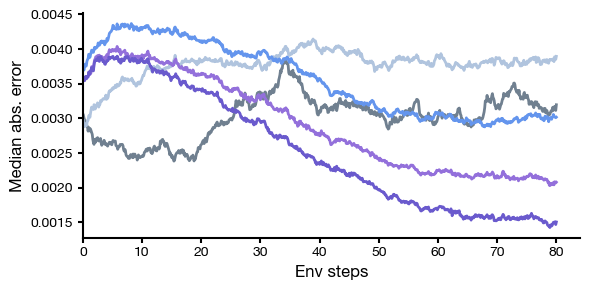

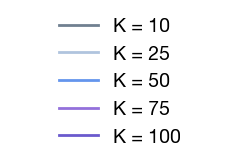

In [249]:
recon_dir = DATA_DIR / "recon"

save_path = FIG_DIR / 'reconstruction/recon_median.png'
# save_path = None

data      = np.load(recon_dir / 'recon_errors.npz')
k_values  = data['k_values'].tolist()

# Override with a custom list of colors, or leave None for viridis default.
RECON_COLORS = ['slategrey', 'lightsteelblue', 'cornflowerblue', 'mediumpurple', 'slateblue']
# RECON_COLORS = None

colors = (RECON_COLORS if RECON_COLORS is not None
          else plt.cm.viridis(np.linspace(0.1, 0.9, len(k_values))))

fig, ax = plt.subplots(figsize=(6, 3))

for k, color in zip(k_values, colors):
    steps  = data[f'{k}_steps'] / 1_0000
    median = data[f'{k}_median']
    ax.plot(steps, median, color=color, lw=2, label=f'K = {k}')

ax.set_xlabel('Env steps', fontsize=12)
ax.set_ylabel('Median abs. error', fontsize=12)
ax.set_xlim(left=0)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()
# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14)
ax_leg.axis("off")
plt.tight_layout()

save_path_leg = FIG_DIR / 'reconstruction/recon_legend.png'
if save_path_leg is not None:
    plt.savefig(save_path_leg, bbox_inches='tight', dpi=300)

plt.show()

# Planning

In [3]:
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5

## Open-Field

### Horizontal

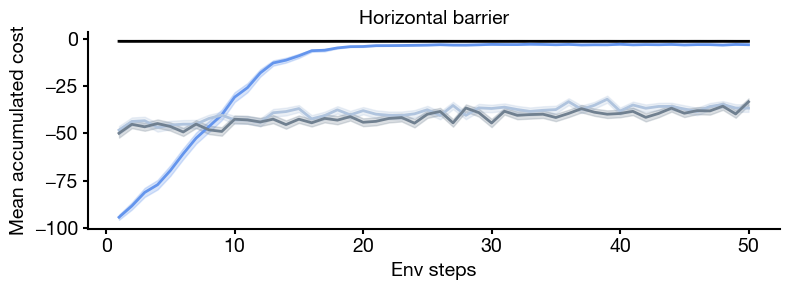

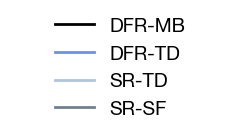

In [29]:
# save_path = FIG_DIR / 'planning/plan_open_H_highlr.png'
save_path = None

data = np.load(DATA_DIR / "planning_open" / "horizontal" / "learning_curves_highlr.npz")

steps = data["checkpoint_steps"] / 10000
fig, ax = plt.subplots(figsize=(8, 3))

for key, label in MODELS.items():
    raw   = data[key].astype(float)
    costs = -0.1 * raw
    mean  = costs.mean(axis=1)
    sem   = costs.std(axis=1) / np.sqrt(raw.shape[1])

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - sem, mean + sem,
                    color=COLORS[key], alpha=0.25)

ax.set_xlabel("Env steps", fontsize=14)
ax.set_ylabel("Mean accumulated cost", fontsize=14)
ax.set_title("Horizontal barrier", fontsize=14)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14)
ax_leg.axis("off")
plt.tight_layout()

# save_path = FIG_DIR / 'legend.png'
save_path = None
if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)
    
plt.show()

### L-barrier

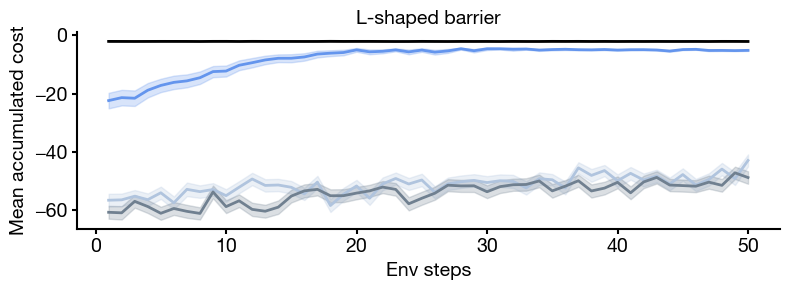

In [30]:
# save_path = FIG_DIR / 'planning/plan_open_L_highlr.png'
save_path = None

data = np.load(DATA_DIR / "planning_open" / "angle" / "learning_curves_full_highlr.npz")

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(8, 3))

for key, label in MODELS.items():
    raw   = data[key].astype(float)
    costs = -0.1 * raw
    mean  = costs.mean(axis=1)
    sem   = costs.std(axis=1) / np.sqrt(raw.shape[1])

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - sem, mean + sem,
                    color=COLORS[key], alpha=0.25)

ax.set_xlabel("Env steps", fontsize=14)
ax.set_ylabel("Mean accumulated cost", fontsize=14)
ax.set_title("L-shaped barrier", fontsize=14)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=14)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

## Four-Room

### Changing goal

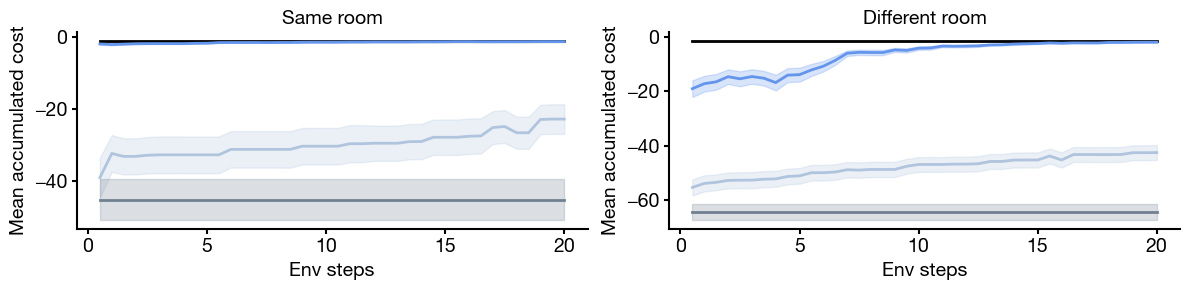

In [12]:
data_goal = np.load(DATA_DIR / "planning_4room" / "goal" / "learning_curves_highlr.npz")

# save_path = FIG_DIR / 'planning/plan_4room_goal_cost_highlr.png'
save_path = None

steps = data_goal["checkpoint_steps"] / 1000

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=False)
titles    = ["Same room", "Different room"]
suffixes  = ["same", "diff"]

for ax, title, suffix in zip(axes, titles, suffixes):
    for key, label in MODELS.items():
        raw = data_goal[f"{key}_{suffix}"].astype(float)   # (n_pairs, n_checkpoints, n_trials)
        costs = -0.1 * raw

        # flatten pairs and trials → (n_checkpoints, n_pairs * n_trials)
        n_pairs, n_ckpt, n_trials = costs.shape
        flat  = costs.transpose(1, 0, 2).reshape(n_ckpt, -1)
        mean  = flat.mean(axis=1)
        sem   = flat.std(axis=1) / np.sqrt(flat.shape[1])

        ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
        ax.fill_between(steps, mean - sem, mean + sem,
                        color=COLORS[key], alpha=0.25)

    ax.set_xlabel("Env steps", fontsize=14)
    ax.set_ylabel("Mean accumulated cost", fontsize=14)
    ax.set_title(title, fontsize=14)
    ax.tick_params(labelsize=14)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

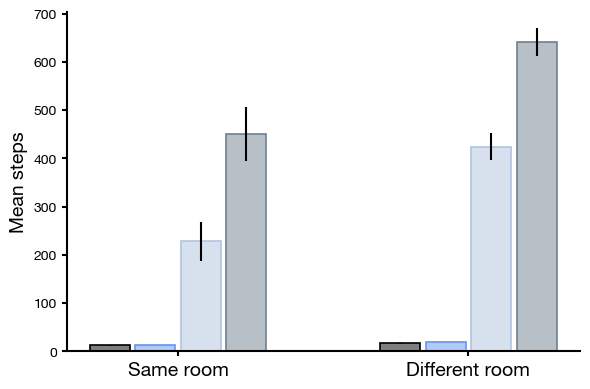

In [14]:
save_path = FIG_DIR / 'planning/plan_4room_goal_final_steps_highlr.png'
# save_path = None

n_models    = len(MODELS)
bar_w       = 0.14
bar_gap     = 0.02                          # between bar gap
bar_spacing = bar_w + bar_gap
group_gap   = 0.4                           # between group gap

offsets = (np.arange(n_models) - (n_models - 1) / 2) * bar_spacing
group_width = (n_models - 1) * bar_spacing + bar_w
centers = np.array([0.0, group_width + group_gap])

fig, ax = plt.subplots(figsize=(6, 4))

for i, (key, label) in enumerate(MODELS.items()):
    fc = (*mcolors.to_rgb(COLORS[key]), 0.5)   # semi-transparent fill
    ec = COLORS[key]                            # solid edge, same hue

    for j, suffix in enumerate(["same", "diff"]):
        raw  = data_goal[f"{key}_{suffix}"][:, -1, :].astype(float)
        flat = raw.flatten()
        mean = flat.mean()
        sem  = flat.std() / np.sqrt(len(flat))

        ax.bar(centers[j] + offsets[i], mean, bar_w,
               facecolor=fc, edgecolor=ec, linewidth=1.2,
               label=label if j == 0 else None,
               yerr=sem, capsize=0,
               error_kw=dict(lw=1.5))

ax.set_xticks(centers)
ax.set_xticklabels(["Same room", "Different room"], fontsize=14)
ax.set_ylabel("Mean steps", fontsize=14)
# ax.set_title("Four-room: steps after full training")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.show()

### Blocked transition

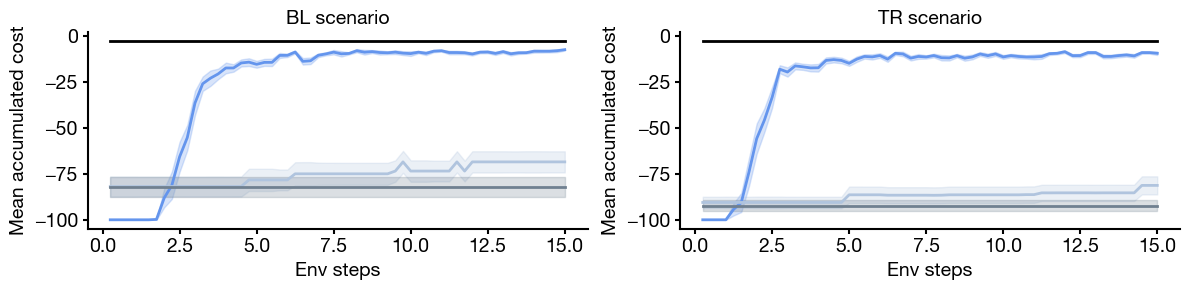

In [15]:
# save_path = FIG_DIR / "planning" / "plan_4room_blocked_cost_highlr.png"
save_path = None

data_blocked = np.load(DATA_DIR / "planning_4room" / "blocked" / "learning_curves_highlr.npz")
steps = data_blocked["checkpoint_steps"] / 10000

# --- learning curves: one panel per scenario ---
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=False)
scenario_titles = {"BL": "BL scenario",
                   "TR": "TR scenario"}

for ax, (scenario_key, title) in zip(axes, scenario_titles.items()):
    for key, label in MODELS.items():
        raw   = data_blocked[f"{key}_{scenario_key}"].astype(float)  # (n_checkpoints, n_trials)
        costs = -0.1 * raw
        mean  = costs.mean(axis=1)
        sem   = costs.std(axis=1) / np.sqrt(raw.shape[1])

        ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
        ax.fill_between(steps, mean - sem, mean + sem,
                        color=COLORS[key], alpha=0.25)

    ax.set_xlabel("Env steps", fontsize=14)
    ax.set_ylabel("Mean accumulated cost", fontsize=14)
    ax.set_title(title, fontsize=14)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=14)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

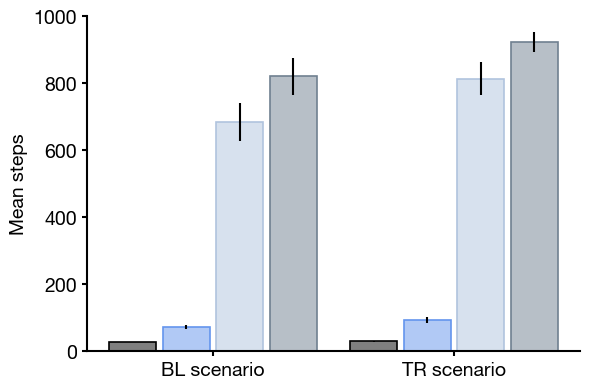

In [17]:
# save_path = FIG_DIR / "planning" / "plan_4room_blocked_final_steps_highlr.png"
save_path = None

n_models    = len(MODELS)
bar_w       = 0.14
bar_gap     = 0.02
bar_spacing = bar_w + bar_gap
group_gap   = 0.1

offsets     = (np.arange(n_models) - (n_models - 1) / 2) * bar_spacing
group_width = (n_models - 1) * bar_spacing + bar_w
centers     = np.array([0.0, group_width + group_gap])

fig, ax = plt.subplots(figsize=(6, 4))

for i, (key, label) in enumerate(MODELS.items()):
    fc = (*mcolors.to_rgb(COLORS[key]), 0.5)
    ec = COLORS[key]

    for j, scenario_key in enumerate(["BL", "TR"]):
        raw  = data_blocked[f"{key}_{scenario_key}"][-1, :].astype(float)  # last checkpoint, all trials
        mean = raw.mean()
        sem  = raw.std() / np.sqrt(len(raw))

        ax.bar(centers[j] + offsets[i], mean, bar_w,
               facecolor=fc, edgecolor=ec, linewidth=1.2,
               label=label if j == 0 else None,
               yerr=sem, capsize=0,
               error_kw=dict(lw=1.5))

ax.set_xticks(centers)
ax.set_xticklabels(["BL scenario", "TR scenario"], fontsize=14)
ax.set_ylabel("Mean steps", fontsize=14)
# ax.set_title("Four-room blocked: steps after full training")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=14)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# Wernle

In [146]:
F_divided = np.load(DATA_DIR / 'wernle' / 'F_divided.npy')
F_merged = np.load(DATA_DIR / 'wernle' / 'F_merged.npy')
SPLIT = 10
ROWS = COLS = 20
N = K = 400

In [ ]:
# Wernle sliding correlation
coords = np.array([[r,c] for r in range(ROWS) for c in range(COLS)])
corr = np.full((N,K), np.nan)
for i in range(N):
    d = np.abs(coords - coords[i])
    succ = np.all(d <= 3, axis=1)
    
    same_comp = (coords[:, 0] < SPLIT) == (coords[i, 0] < SPLIT)
    succ = succ & same_comp
    
    if succ.sum() < 4: continue
    for k in range(K):
        b = F_divided[succ,k]; a = F_merged[succ,k]
        if np.std(b)<1e-10 or np.std(a)<1e-10: continue
        corr[i,k] = spearmanr(b,a).correlation

mm = np.nanmean(corr, axis=1).reshape(ROWS,COLS)
rp = np.nanmean(mm, axis=1)

wall_rows = slice(SPLIT-2, SPLIT+2)
distal_rows = list(range(3)) + list(range(ROWS-3, ROWS))

In [ ]:
mm.shape

(20, 20)

## Across all grid cells

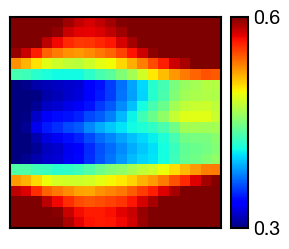

In [ ]:
# save_path = FIG_DIR / "wernle" / "corr_map_all_2.png"
save_path = None

fig, ax = plt.subplots(figsize=(3, 3))
vmin = 0.3
vmax = 0.6
im = ax.imshow(mm, cmap='jet', origin='lower', vmin=vmin, vmax=vmax)
ax.set_xticks([])
ax.set_yticks([])
 
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="8%", pad=0.1)
cb = plt.colorbar(im, cax=cax)
cb.set_ticks([vmin, vmax])
cb.ax.tick_params(length=0, labelsize=14)
 
plt.tight_layout()
if save_path is not None:
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

## Specific grid cells

In [144]:

# save_path = FIG_DIR / "wernle" / "corr_map_individual.png"
# save_path = None
# vmin = 0.7
# vmax = 1.0

# feat_indices = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
# n_feat = len(feat_indices)
# fig, axes = plt.subplots(n_feat, 3, figsize=(10, 3*n_feat))
# for row, k in enumerate(feat_indices):
#     map_b = F_divided[:, k].reshape(ROWS, COLS)
#     map_a = F_merged[:, k].reshape(ROWS, COLS)
#     map_c = corr[:, k].reshape(ROWS, COLS)
#     axes[row,0].imshow(map_b, origin='lower', cmap='jet')
#     axes[row,0].set_title(f'F_divided (feat {k})')
#     axes[row,1].imshow(map_a, origin='lower', cmap='jet')
#     axes[row,1].set_title(f'F_merged (feat {k})')
#     im = axes[row,2].imshow(map_c, origin='lower', cmap='jet', vmin=vmin, vmax=vmax)
#     axes[row,2].set_title(f'Corr (feat {k})')
#     plt.colorbar(im, ax=axes[row,2], shrink=0.8)
#     for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])
 
# plt.tight_layout()
# if save_path is not None:
#     plt.savefig(save_path, dpi=300, bbox_inches='tight')
# plt.show()

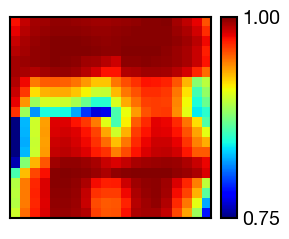

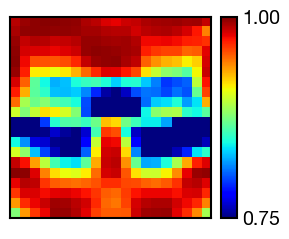

In [145]:
features = [7, 8]
# save_dir = FIG_DIR / "wernle"
save_dir = None
vmin = 0.75
vmax = 1.0
for k in features:
    fig, ax = plt.subplots(figsize=(3, 3))
    map_c = corr[:, k].reshape(ROWS, COLS)
    im = ax.imshow(map_c, cmap='jet', origin='lower', vmin=vmin, vmax=vmax)
    ax.set_xticks([])
    ax.set_yticks([])
    
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="8%", pad=0.1)
    cb = plt.colorbar(im, cax=cax)
    cb.set_ticks([vmin, vmax])
    cb.ax.tick_params(length=0, labelsize=14)
    
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / f"corr_map_individual_f{k}.png", dpi=300, bbox_inches='tight')
    plt.show()

# Model Comparison with Dyna-Q

In [22]:
MODELS = {
    "woodbury_feat": "DFR-MB",
    "woodbury_td":   "DFR-TD",
    "dyna_q_k5":     "Dyna-Q-5",
    "dyna_q_k10":    "Dyna-Q-10",
    "dyna_q_k20":    "Dyna-Q-20",
    "dyna_q_k50":    "Dyna-Q-50",
}
COLORS = {
    "woodbury_feat": "black",
    "woodbury_td":   "cornflowerblue",
    "dyna_q_k5":     "lightsteelblue",
    "dyna_q_k10":    "slategrey",
    "dyna_q_k20":    "mediumslateblue",
    "dyna_q_k50":    "mediumpurple",
}


## Horizontal

In [23]:
data = np.load(DATA_DIR / "planning_open" / "horizontal_mc" / "learning_curves_lr0.01.npz")

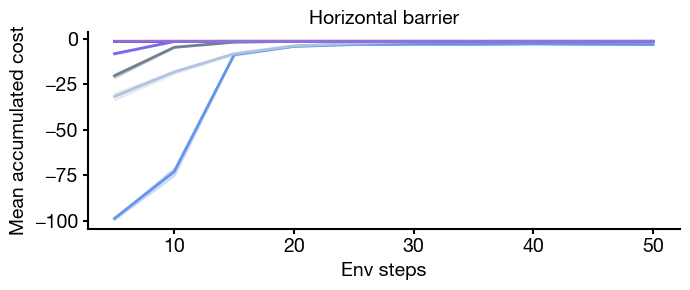

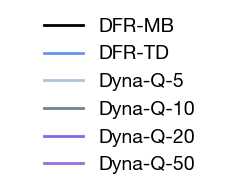

In [25]:
# save_path = FIG_DIR / 'planning/plan_open_H_MC.png'
save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(7, 3))

for key, label in MODELS.items():
    raw   = data[key].astype(float)
    costs = -0.1 * raw
    mean  = costs.mean(axis=1)
    sem   = costs.std(axis=1) / np.sqrt(raw.shape[1])

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - sem, mean + sem,
                    color=COLORS[key], alpha=0.25)

ax.set_xlabel("Env steps", fontsize=14)
ax.set_ylabel("Mean accumulated cost", fontsize=14)
ax.set_title("Horizontal barrier", fontsize=14)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14)
ax_leg.axis("off")
plt.tight_layout()

# save_path = FIG_DIR / 'legend_MC.png'
save_path = None
if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)
    
plt.show()

## L-Shape

In [32]:
data = np.load(DATA_DIR / "planning_open" / "angle_mc" / "learning_curves_lr0.01.npz")

woodbury_feat 13.95
woodbury_td 31.69
dyna_q_k5 13.92
dyna_q_k10 14.37
dyna_q_k20 14.41
dyna_q_k50 14.4


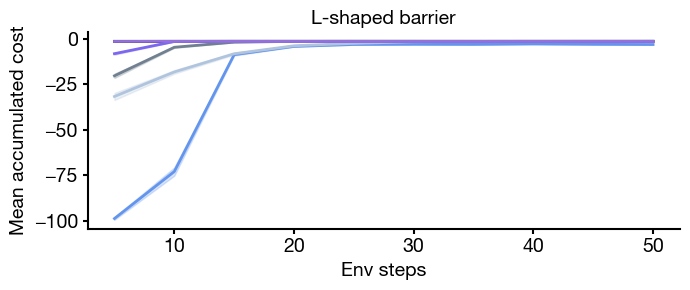

In [26]:
# save_path = FIG_DIR / 'planning/plan_open_L_MC.png'
save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(7, 3))

for key, label in MODELS.items():
    raw   = data[key].astype(float)
    print(key, raw[-1].mean())
    costs = -0.1 * raw
    mean  = costs.mean(axis=1)
    sem   = costs.std(axis=1) / np.sqrt(raw.shape[1])

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - sem, mean + sem,
                    color=COLORS[key], alpha=0.25)

ax.set_xlabel("Env steps", fontsize=14)
ax.set_ylabel("Mean accumulated cost", fontsize=14)
ax.set_title("L-shaped barrier", fontsize=14)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# Planning with different K

In [ ]:
K = [50, 75, 100, 125, 150, 175, 200, 220, 225]

cmap_p = plt.get_cmap("Purples")
cmap_b = plt.get_cmap("Blues")
COLORS_BLUE = cmap_b(np.linspace(0.3, 0.5, len(K)//2))
COLORS_PURPLE = cmap_p(np.linspace(0.5, 0.9, len(K)//2+1))
COLORS = np.concatenate((COLORS_BLUE, COLORS_PURPLE))
# COLORS = ["dimgrey", "slategrey", "lightslategrey", "lightsteelblue", 
#           "lavender", "cornflowerblue", "royalblue", "mediumslateblue", "mediumpurple",
# ]

plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5

## Angle

In [100]:
data = np.load(DATA_DIR / "planning_open" / "angle" / "num_steps_K.npz")

In [105]:
for k in K:
    print(f"K = {k}")
    td_name = f"woodbury_td_K{k}"
    feat_name = f"woodbury_feat_K{k}"
    
    mean_td = data[td_name].astype(float)[-1].mean()
    mean_feat = data[feat_name].astype(float)[-1].mean()
    print(f"feat: {mean_feat} | td: {mean_td}")

K = 50
feat: 962.61 | td: 155.035
K = 75
feat: 944.765 | td: 113.96
K = 100
feat: 857.645 | td: 113.76
K = 125
feat: 965.08 | td: 85.68
K = 150
feat: 980.695 | td: 80.875
K = 175
feat: 989.465 | td: 71.765
K = 200
feat: 932.48 | td: 59.345
K = 220
feat: 43.465 | td: 50.085
K = 225
feat: 29.465 | td: 50.665


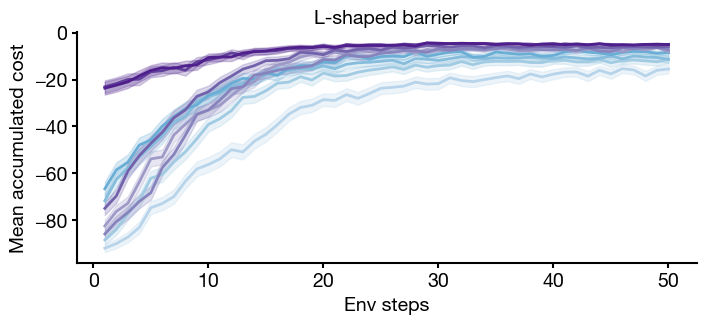

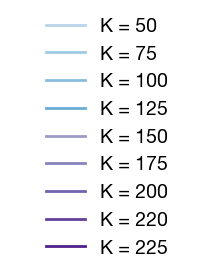

In [ ]:
# save_path = FIG_DIR / 'planning/plan_open_L_K.png'
save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(8, 3))

for i, k in enumerate(K):
    model_name = f"woodbury_td_K{k}"
    raw   = data[model_name].astype(float)
    costs = -0.1 * raw
    mean  = costs.mean(axis=1)
    sem   = costs.std(axis=1) / np.sqrt(raw.shape[1])

    label = f"K = {K[i]}"
    ax.plot(steps, mean, color=COLORS[i], lw=2, label=label)
    ax.fill_between(steps, mean - sem, mean + sem,
                    color=COLORS[i], alpha=0.25)

ax.set_xlabel("Env steps", fontsize=14)
ax.set_ylabel("Mean accumulated cost", fontsize=14)
ax.set_title("L-shaped barrier", fontsize=14)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)

# plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14)
ax_leg.axis("off")
# plt.tight_layout()

# save_path = FIG_DIR / 'legend_K.png'
save_path = None
if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)
    
plt.show()

## Horizontal

In [106]:
data = np.load(DATA_DIR / "planning_open" / "horizontal" / "num_steps_K.npz")

In [107]:
for k in K:
    print(f"K = {k}")
    td_name = f"woodbury_td_K{k}"
    feat_name = f"woodbury_feat_K{k}"
    
    mean_td = data[td_name].astype(float)[-1].mean()
    mean_feat = data[feat_name].astype(float)[-1].mean()
    print(f"feat: {mean_feat} | td: {mean_td}")

K = 50
feat: 795.3 | td: 294.39
K = 75
feat: 733.37 | td: 184.695
K = 100
feat: 757.18 | td: 97.24
K = 125
feat: 586.735 | td: 38.12
K = 150
feat: 651.545 | td: 41.21
K = 175
feat: 872.015 | td: 39.16
K = 200
feat: 739.105 | td: 39.92
K = 220
feat: 13.56 | td: 32.82
K = 225
feat: 13.6 | td: 32.78


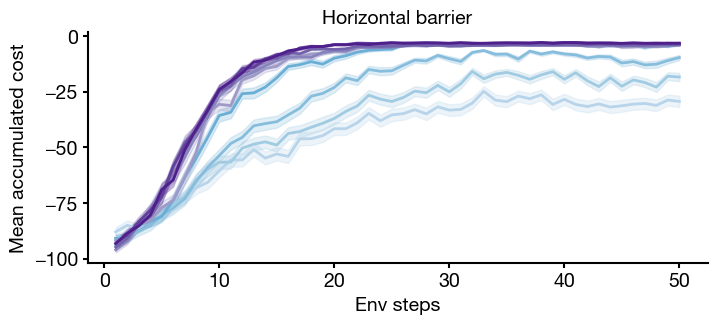

In [ ]:
# save_path = FIG_DIR / 'planning/plan_open_Horizontal_K.png'
# save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(8, 3))

for i, k in enumerate(K):
    model_name = f"woodbury_td_K{k}"
    raw   = data[model_name].astype(float)
    costs = -0.1 * raw
    mean  = costs.mean(axis=1)
    sem   = costs.std(axis=1) / np.sqrt(raw.shape[1])

    label = f"K = {K[i]}"
    ax.plot(steps, mean, color=COLORS[i], lw=2, label=label)
    ax.fill_between(steps, mean - sem, mean + sem,
                    color=COLORS[i], alpha=0.25)

ax.set_xlabel("Env steps", fontsize=14)
ax.set_ylabel("Mean accumulated cost", fontsize=14)
ax.set_title("Horizontal barrier", fontsize=14)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)

# plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()